# micrograd

Following Andrej Karpathy's lecture [The spelled-out intro to neural networks and backpropagation: building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0&list=PLXYLzZ3XzIbi4lL43O6fIU_ojuZwBO6vi).

In [1]:
import math
import typing
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

[4, 5, 8, 1, 4, 5, 8, 1]


In [2]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        out = Value(self.data + val.data, (self, val), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            val.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __radd__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return self + val

    def __sub__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        out = Value(self.data - val.data, (self, val), '-')

        def _backward():
            self.grad += 1.0 * out.grad
            val.grad -= 1.0 * out.grad

        out._backward = _backward
        return out


    def __rsub__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return val - self

    def __mul__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        out =  Value(self.data * val.data, (self, val), '*')

        def _backward():
            self.grad += val.data * out.grad
            val.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return self * val

    def __truediv__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return self * val**-1.0

    def __rtruediv__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return val/self

    def __pow__(self, val):
        assert isinstance(val, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**val, (self, ), f'**{val}')

        def _backward():
            self.grad += val* out.data / self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        out =  Value( np.tanh(self.data), (self, ), 'tanh')
        def _backward():
            self.grad += (1.0 - out.data**2.0) * out.grad

        out._backward = _backward
        return out

    def exp(self):
        out = Value (np.exp(self.data), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        # this is probably not the smartest idea.
        # better extract the zeroing of the gradient into a separate method
        for val in topo:
            val.grad = 0.0
        self.grad = 1.0
        for val in reversed(topo):
            val._backward()


In [3]:
from graphviz import Digraph
def trace(root):
    nodes = set()
    edges = set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = f"{{ {n.label} | data: {n.data:.4f} | grad: {n.grad:.4f} }}", shape = 'record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


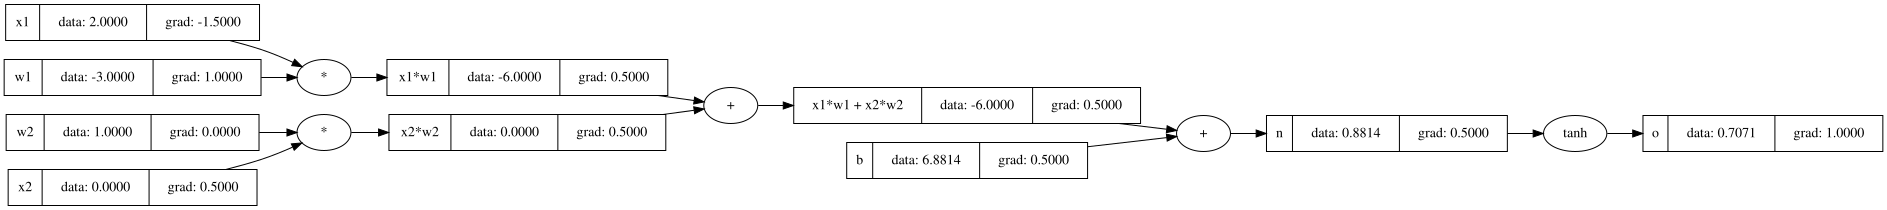

In [4]:
# inputs x1, x2
x1 = Value(2.0, label ='x1')
x2 = Value(0.0, label ='x2')
# weights w1, w2
w1 = Value(-3.0, label ='w1')
w2 = Value(1.0, label ='w2')
# bias of the neuron
b = Value (6.8813735870195432, label ='b')
# x1*w1 + x2*w1 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.grad = 1.0
o.backward()
draw_dot(o)

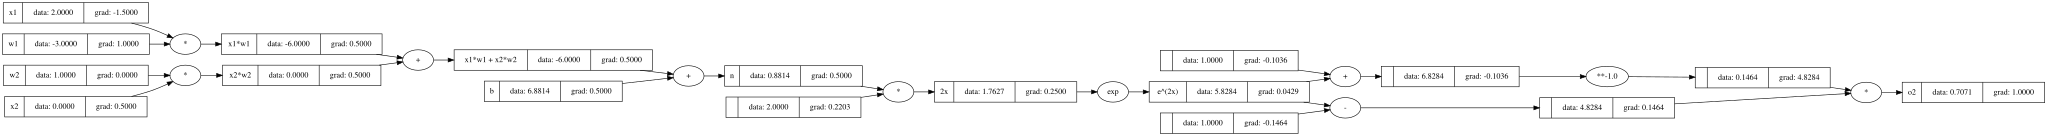

In [5]:
# This demonstrates that if we express tanh(x) by its elementary functions, the gradients are still tracked correctly
n2 = 2*n; n2.label = '2x'
en2 = n2.exp(); en2.label = 'e^(2x)'
o2 = (en2-1)/(en2+1); o2.label = 'o2'

o2.grad = 1.0
o2.backward()
draw_dot(o2)

In [13]:
# this is just an illustration how we would setup such a computational graph using pytorch
import torch

x1 = torch.Tensor([2.0]).double()  ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()  ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()  ; w2.requires_grad = True
b = torch.tensor([6.8813735870195432]).double() ; b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())


0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [7]:
class Neuron:

    def __init__(self, nin: typing.SupportsIndex):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w * x + b
        act = sum((w_i*x_i for w_i, x_i in zip(self.w, x)), self.b)
        return act.tanh()

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin: typing.SupportsIndex, n_neurons: typing.SupportsIndex):
        self.neurons = [Neuron(nin) for _ in range(n_neurons)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for n_ in self.neurons for p in n_.parameters() ]

class MLP:

    def __init__(self, nin: int, nouts: typing.List[int]):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        # this ensures that the computational graph using the Value instances are re-established and the results are calculated
        # the parameters (weights and bias Value nodes) are not affected here and are re-used
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for l_ in self.layers for p in l_.parameters() ]

In [8]:
n = MLP(3, [4, 4, 1])
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets


In [15]:
# This computes the total loss function by creating the computational graph for each training data set and then create the loss "node" (Value instance)
# as the squared sum of the squared differences between the really resulting values and the desired value for each training data "point" (input vector)
def L(xs_: typing.List[typing.List[float]], ys_: typing.List[float], n_: MLP):
    y_real = [ n_(x) for x in xs_ ]
    l_ = sum( (ygt - yout)**2 for ygt, yout in zip(ys_, y_real))
    return l_

In [10]:
# This is a bit more sophisticated optimization function implementing the gradient descent method with adaptive step width.
def optimize(inital_factor: float, max_tolerable_loss: float, max_steps: int, xs_: typing.List[typing.List[float]], ys_: typing.List[float], n_: MLP, min_factor: float = 1e-6):
    factor = inital_factor
    steps = 0
    assert max_steps > 0
    while True:
        if steps > max_steps:
            print(f"optimizing: reaching acceptable target loss {max_tolerable_loss} failed in {max_steps} steps: residual loss: {loss.data}")
            break
        # re-establish the computation graph leading to the Value instance containing the loss
        # it also recalculates the loss value
        loss = L(xs_, ys_, n_)
        if loss.data < max_tolerable_loss:
            print(f"optimizing: residual loss {loss.data} < reaching acceptable target loss {max_tolerable_loss} after {steps} steps")
            break
        print(f"step #{steps}: loss: {loss.data}, factor: {factor}")
        # now do the back-propagation (in my version backward() zeroes the gradients first. Karpathy uses an extra method to do this before calling backward()
        loss.backward()
        params = n_.parameters()
        # this just backups the old data (the values), so that we can do a test stop and - if the loss is not shrinking - restore the old values to retry with a smaller step width
        old_data = [p.data for p in params]
        factor *= 2.0  # first probe a doubled step width
        while True:
            for p, d in zip(params, old_data):
                # d contains the "old" params and p the "new" params if we would use factor
                p.data = d - factor*p.grad
            if L(xs_, ys_, n_).data < loss.data:
                break  # the loss shrinks: keep this factor
            # the larger factor led to an increase of the loss value => factor is too large
            # => shrink it by dividing it by two until the
            factor /= 2.0  # step too wide: divide factor by 2 and probe again
            # if the factor drops below a certain threshold while the new loss would still be larger than the old one, assume that
            # it doesn't converge. Therefore, restore the old parameters and abort with an error message
            if factor < min_factor:
                for p, d in zip(params, old_data):
                    p.data = d
                print(f"optimizing: reaching acceptable target loss {max_tolerable_loss} failed after {steps} steps: no factor >= {min_factor} reduces the loss {loss.data}")
                return
        steps += 1


In [17]:
# This is the final code
# create the MLP with random weights and biases for each neuron
n = MLP(3, [4, 4, 1])
# now set the training data: four data "points" consisting of three input values
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
# those are the desired target value
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

# now call the optimize function
optimize(0.2, 1.0e-5, 200, xs, ys, n)

step #0: loss: 6.662250777103427, factor: 0.2
step #1: loss: 2.142920140145949, factor: 0.4
step #2: loss: 1.9323150161099807, factor: 0.2
step #3: loss: 0.044274837070318006, factor: 0.1
step #4: loss: 0.01558439192021671, factor: 0.2
step #5: loss: 0.009241919938681292, factor: 0.4
step #6: loss: 0.005327503408928857, factor: 0.8
step #7: loss: 0.002977764782277888, factor: 1.6
step #8: loss: 0.001631410193515017, factor: 3.2
step #9: loss: 0.0008927256908315053, factor: 6.4
step #10: loss: 0.0004962623391139002, factor: 12.8
step #11: loss: 0.0002802667516902632, factor: 25.6
step #12: loss: 0.00015647272872142026, factor: 51.2
step #13: loss: 8.334549006492848e-05, factor: 102.4
step #14: loss: 4.2105240261276665e-05, factor: 204.8
step #15: loss: 2.0622368921293972e-05, factor: 409.6
optimizing: residual loss 9.993560739151917e-06 < reaching acceptable target loss 1e-05 after 16 steps
